# Task 3 — Real-World Dataset Analysis

In this notebook, I explore World Bank annual data for Bangladesh, India, Nepal, Pakistan, and Sri Lanka from 2000 through 2024. I examine GDP per capita in constant 2015 US dollars and life expectancy at birth in years. The report and README cite the original indicator pages and API documentation.

## 1. Load and inspect the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = Path('data/south_asia_wdi_2000_2024.csv')
df = pd.read_csv(DATA)
print('Shape:', df.shape)
print('Years:', df.year.min(), 'to', df.year.max())
print('Countries:', sorted(df.country.unique()))
df.head()

Shape: (125, 5)
Years: 2000 to 2024
Countries: ['Bangladesh', 'India', 'Nepal', 'Pakistan', 'Sri Lanka']


,country_code,country,year,gdp_pc_2015_usd,life_expectancy_years
0,BGD,Bangladesh,2000,620.560473,62.049
1,BGD,Bangladesh,2001,641.288923,62.836
2,BGD,Bangladesh,2002,655.672139,63.591
3,BGD,Bangladesh,2003,676.826252,64.288
4,BGD,Bangladesh,2004,702.656357,64.912


## 2. Validate completeness and record keys

In [2]:
print('Missing values by column:\n', df.isna().sum())
print('Duplicate country-year records:', int(df.duplicated(['country_code','year']).sum()))
print('Non-positive GDP per capita:', int((df.gdp_pc_2015_usd <= 0).sum()))
print('Life expectancy outside 0–120 years:', int((~df.life_expectancy_years.between(0,120)).sum()))
assert len(df) == 125 and df.isna().sum().sum() == 0
assert not df.duplicated(['country_code','year']).any()

Missing values by column:
 country_code             0
country                  0
year                     0
gdp_pc_2015_usd          0
life_expectancy_years    0
dtype: int64
Duplicate country-year records: 0
Non-positive GDP per capita: 0
Life expectancy outside 0–120 years: 0


## 3. Compare endpoints and changes

In [3]:
rows=[]
for country, g in df.groupby('country'):
    g=g.sort_values('year').set_index('year')
    a,b=g.loc[2000],g.loc[2024]
    rows.append({'country':country,'GDP pc 2000 (2015 US$)':a.gdp_pc_2015_usd,'GDP pc 2024 (2015 US$)':b.gdp_pc_2015_usd,'GDP pc change (%)':(b.gdp_pc_2015_usd/a.gdp_pc_2015_usd-1)*100,'Life expectancy 2000':a.life_expectancy_years,'Life expectancy 2024':b.life_expectancy_years,'Life expectancy change (years)':b.life_expectancy_years-a.life_expectancy_years})
summary=pd.DataFrame(rows).sort_values('GDP pc change (%)',ascending=False).reset_index(drop=True)
summary.round(2)

,country,GDP pc 2000 (2015 US$),GDP pc 2024 (2015 US$),GDP pc change (%),Life expectancy 2000,Life expectancy 2024,Life expectancy change (years)
0,Bangladesh,620.56,1941.28,212.83,62.05,74.93,12.88
1,India,756.70,2366.83,212.78,62.75,72.24,9.49
2,Nepal,547.22,1179.95,115.63,62.64,70.64,7.99
3,Sri Lanka,1956.93,4198.75,114.56,71.18,77.67,6.49
4,Pakistan,1049.54,1635.09,55.79,61.90,67.80,5.90


## 4. Describe the association carefully
The pooled correlation below is descriptive only. Country-level differences and shared time trends can affect it; it does not show that changes in GDP per capita cause changes in life expectancy.

In [4]:
pooled_r=df.gdp_pc_2015_usd.corr(df.life_expectancy_years)
within=df.groupby('country').apply(lambda g:g.gdp_pc_2015_usd.corr(g.life_expectancy_years),include_groups=False).rename('within-country Pearson r')
print('Pooled Pearson r:',round(pooled_r,4))
within

Pooled Pearson r: 0.8354


country
Bangladesh    0.957951
India         0.947873
Nepal         0.943702
Pakistan      0.956859
Sri Lanka     0.881703
Name: within-country Pearson r, dtype: float64

## 5. Visualize the panel

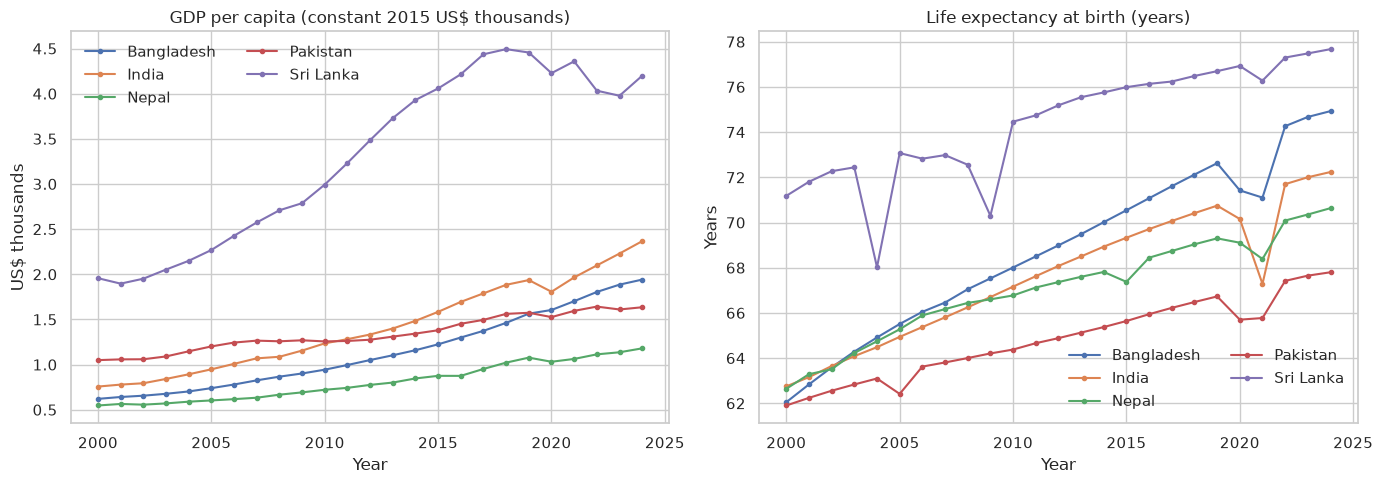

In [5]:
sns.set_theme(style='whitegrid')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for country,g in df.groupby('country'):
    axes[0].plot(g.year,g.gdp_pc_2015_usd/1000,marker='o',ms=3,label=country)
    axes[1].plot(g.year,g.life_expectancy_years,marker='o',ms=3,label=country)
axes[0].set(title='GDP per capita (constant 2015 US$ thousands)',xlabel='Year',ylabel='US$ thousands')
axes[1].set(title='Life expectancy at birth (years)',xlabel='Year',ylabel='Years')
for ax in axes: ax.legend(frameon=False,ncol=2)
plt.tight_layout()
plt.show()

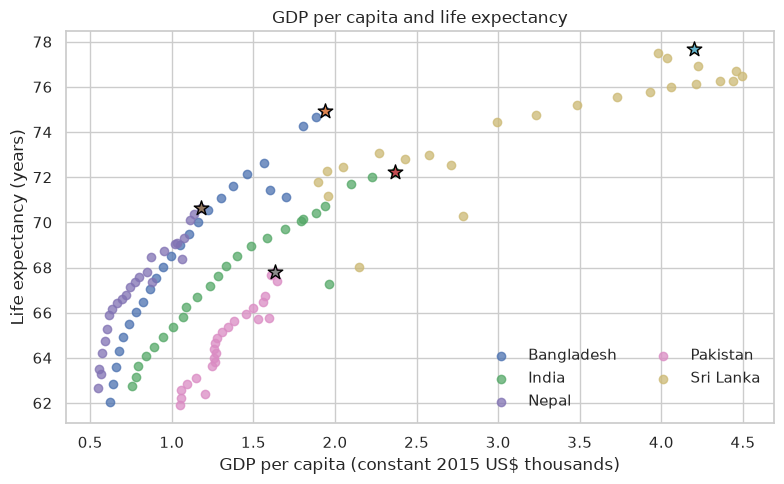

In [6]:
fig,ax=plt.subplots(figsize=(8,5))
for country,g in df.groupby('country'):
    ax.scatter(g.gdp_pc_2015_usd/1000,g.life_expectancy_years,label=country,alpha=.75)
    last=g[g.year==2024].iloc[0]
    ax.scatter(last.gdp_pc_2015_usd/1000,last.life_expectancy_years,marker='*',s=120,edgecolor='black')
ax.set(title='GDP per capita and life expectancy',xlabel='GDP per capita (constant 2015 US$ thousands)',ylabel='Life expectancy (years)')
ax.legend(frameon=False,ncol=2)
plt.tight_layout(); plt.show()

## References
- World Bank GDP per capita, constant 2015 US$: https://data.worldbank.org/indicator/NY.GDP.PCAP.KD
- World Bank life expectancy at birth, total: https://data.worldbank.org/indicator/SP.DYN.LE00.IN
- World Bank Indicators API documentation: https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api-documentation